In [27]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import os
import zipfile


# Set random seed for reproducibility
torch.manual_seed(0)



In [28]:

DATA_DIR = "data"
# For each task: Hugging Face dataset name, image column, train split, test split.
SOURCES = {
    "mnist":      ("ylecun/mnist",                     "image", "train", "test"),
    "cifar10":    ("uoft-cs/cifar10",                  "img",   "train", "test"),
    "imagenet32": ("benjamin-paine/imagenet-1k-32x32", "image", "train", "validation"),
}


def load_task(task):
    """Return X_train, y_train, X_test, y_test, downloading only if there is no saved copy.

    The arrays are memory-mapped: they are read from disk as they are used
    instead of all being loaded into RAM up front.
    """
    folder = os.path.join(DATA_DIR, task)
    old_file = os.path.join(DATA_DIR, f"{task}.npz")   # saved by an earlier version of this notebook

    if not os.path.isdir(folder) and os.path.exists(old_file):
        # Unpack the earlier single-file copy into the folder format; no download needed.
        print(f"{task}: unpacking {old_file} (one time only; you can delete it afterwards)")
        temp_folder = folder + ".partial"
        os.makedirs(temp_folder, exist_ok=True)
        # An .npz file is a zip of .npy files, so extracting it streams them to disk
        # without loading the arrays into memory.
        with zipfile.ZipFile(old_file) as old:
            old.extractall(temp_folder)
        os.replace(temp_folder, folder)

    # mmap_mode="c" (copy-on-write): read from disk on demand, and any changes
    # your code makes to the arrays stay in memory and never touch the files.
    return tuple(np.load(os.path.join(folder, f"{part}.npy"), mmap_mode="c")
                 for part in ["X_train", "y_train", "X_test", "y_test"])

In [29]:


# -------------------------------------------------------------------------
# 1. Load Datasets (3 CIFAR-10 images and 3 ImageNet32-style images)
# -------------------------------------------------------------------------
sample_size = 5
# Load CIFAR-10
cifar_images, cifar_labels, _, _ = load_task('cifar10')
random_indices = np.random.choice(cifar_images.shape[0], size=sample_size, replace=False)
cifar_images = torch.as_tensor(cifar_images[random_indices])
cifar_labels = torch.as_tensor(cifar_labels[random_indices])

imagenet_images, imagenet_labels, _, _ = load_task('imagenet32')
random_indices = np.random.choice(imagenet_images.shape[0], size=sample_size, replace=False)
imagenet_images = torch.as_tensor(imagenet_images[random_indices])
imagenet_labels = torch.as_tensor(imagenet_labels[random_indices])

stacked = torch.stack([cifar_images, imagenet_images], dim=0)
labels = torch.stack([cifar_labels, imagenet_labels], dim=0)

del(cifar_images, cifar_labels, imagenet_images, imagenet_labels)


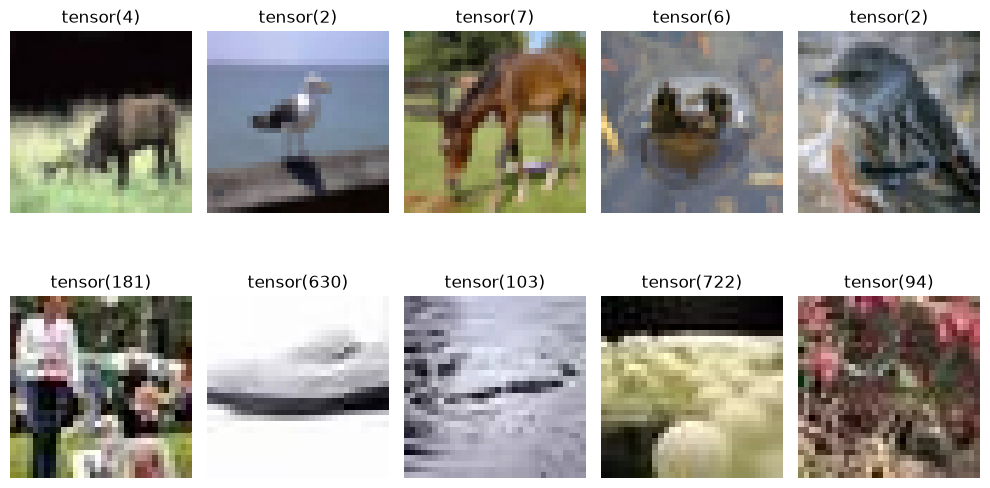

In [30]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=stacked.shape[0], ncols=stacked.shape[1], figsize=(10, 6), squeeze=False)
for row in range(stacked.shape[0]):
    for col in range(stacked.shape[1]):
        img_tensor = stacked[row, col]
        
        # Convert CHW -> HWC for matplotlib display
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        
        # Normalize pixel values to [0, 1] range if needed for display
        if img_np.max() > 1.0 or img_np.min() < 0.0:
            img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-5)
            
        ax = axes[row, col]
        ax.imshow(img_np)
        ax.set_title(labels[row, col])
        ax.axis('off')

plt.tight_layout()
plt.show()

In [31]:

# -------------------------------------------------------------------------
# 2. Define 10 Most Common Torchvision Transformations & Parameters
# -------------------------------------------------------------------------
# Note: For tensor-only transforms like Normalize and RandomErasing, 
# ToTensor is prepended to show the converted/transformed output properly.

transform_definitions = [
    ("RandomResizedCrop", transforms.RandomResizedCrop(size=(32, 32), scale=(0.5, 1.0), ratio=(0.75, 1.33)), "size=(32,32), scale=(0.5, 1.0)"),
    ("RandomHorizontalFlip", transforms.RandomHorizontalFlip(p=1.0), "p=1.0 (forced for visual)"),
    ("ColorJitter", transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1), "brightness=0.4, contrast=0.4, hue=0.1"),
    ("RandomRotation", transforms.RandomRotation(degrees=(-30, 30)), "degrees=(-30, 30)"),
    ("RandomAffine", transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10), "degrees=15, translate=(0.1,0.1), shear=10"),
    ("GaussianBlur", transforms.GaussianBlur(kernel_size=(3, 3), sigma=(1.0, 2.0)), "kernel_size=(3,3), sigma=(1.0, 2.0)"),
    ("RandomPerspective", transforms.RandomPerspective(distortion_scale=0.5, p=1.0), "distortion_scale=0.5, p=1.0"),
    ("CenterCrop", transforms.CenterCrop(size=(20, 20)), "size=(20, 20)"),
    ("Normalize", transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])]), "mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]"),
    ("RandomErasing", transforms.Compose([transforms.ToTensor(), transforms.RandomErasing(p=1.0, scale=(0.1, 0.3), value='random')]), "p=1.0, scale=(0.1, 0.3), value='random'")
]

# Helper to prepare image display in matplotlib
def denormalize_and_format(img_obj):
    if isinstance(img_obj, torch.Tensor):
        img_np = img_obj.cpu().numpy()
        if img_np.shape[0] == 3:  # CHW -> HWC
            img_np = np.transpose(img_np, (1, 2, 0))
        # Min-Max normalize tensor values back to [0, 1] range for Matplotlib visualization
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-5)
        return img_np
    else:
        return np.array(img_obj)


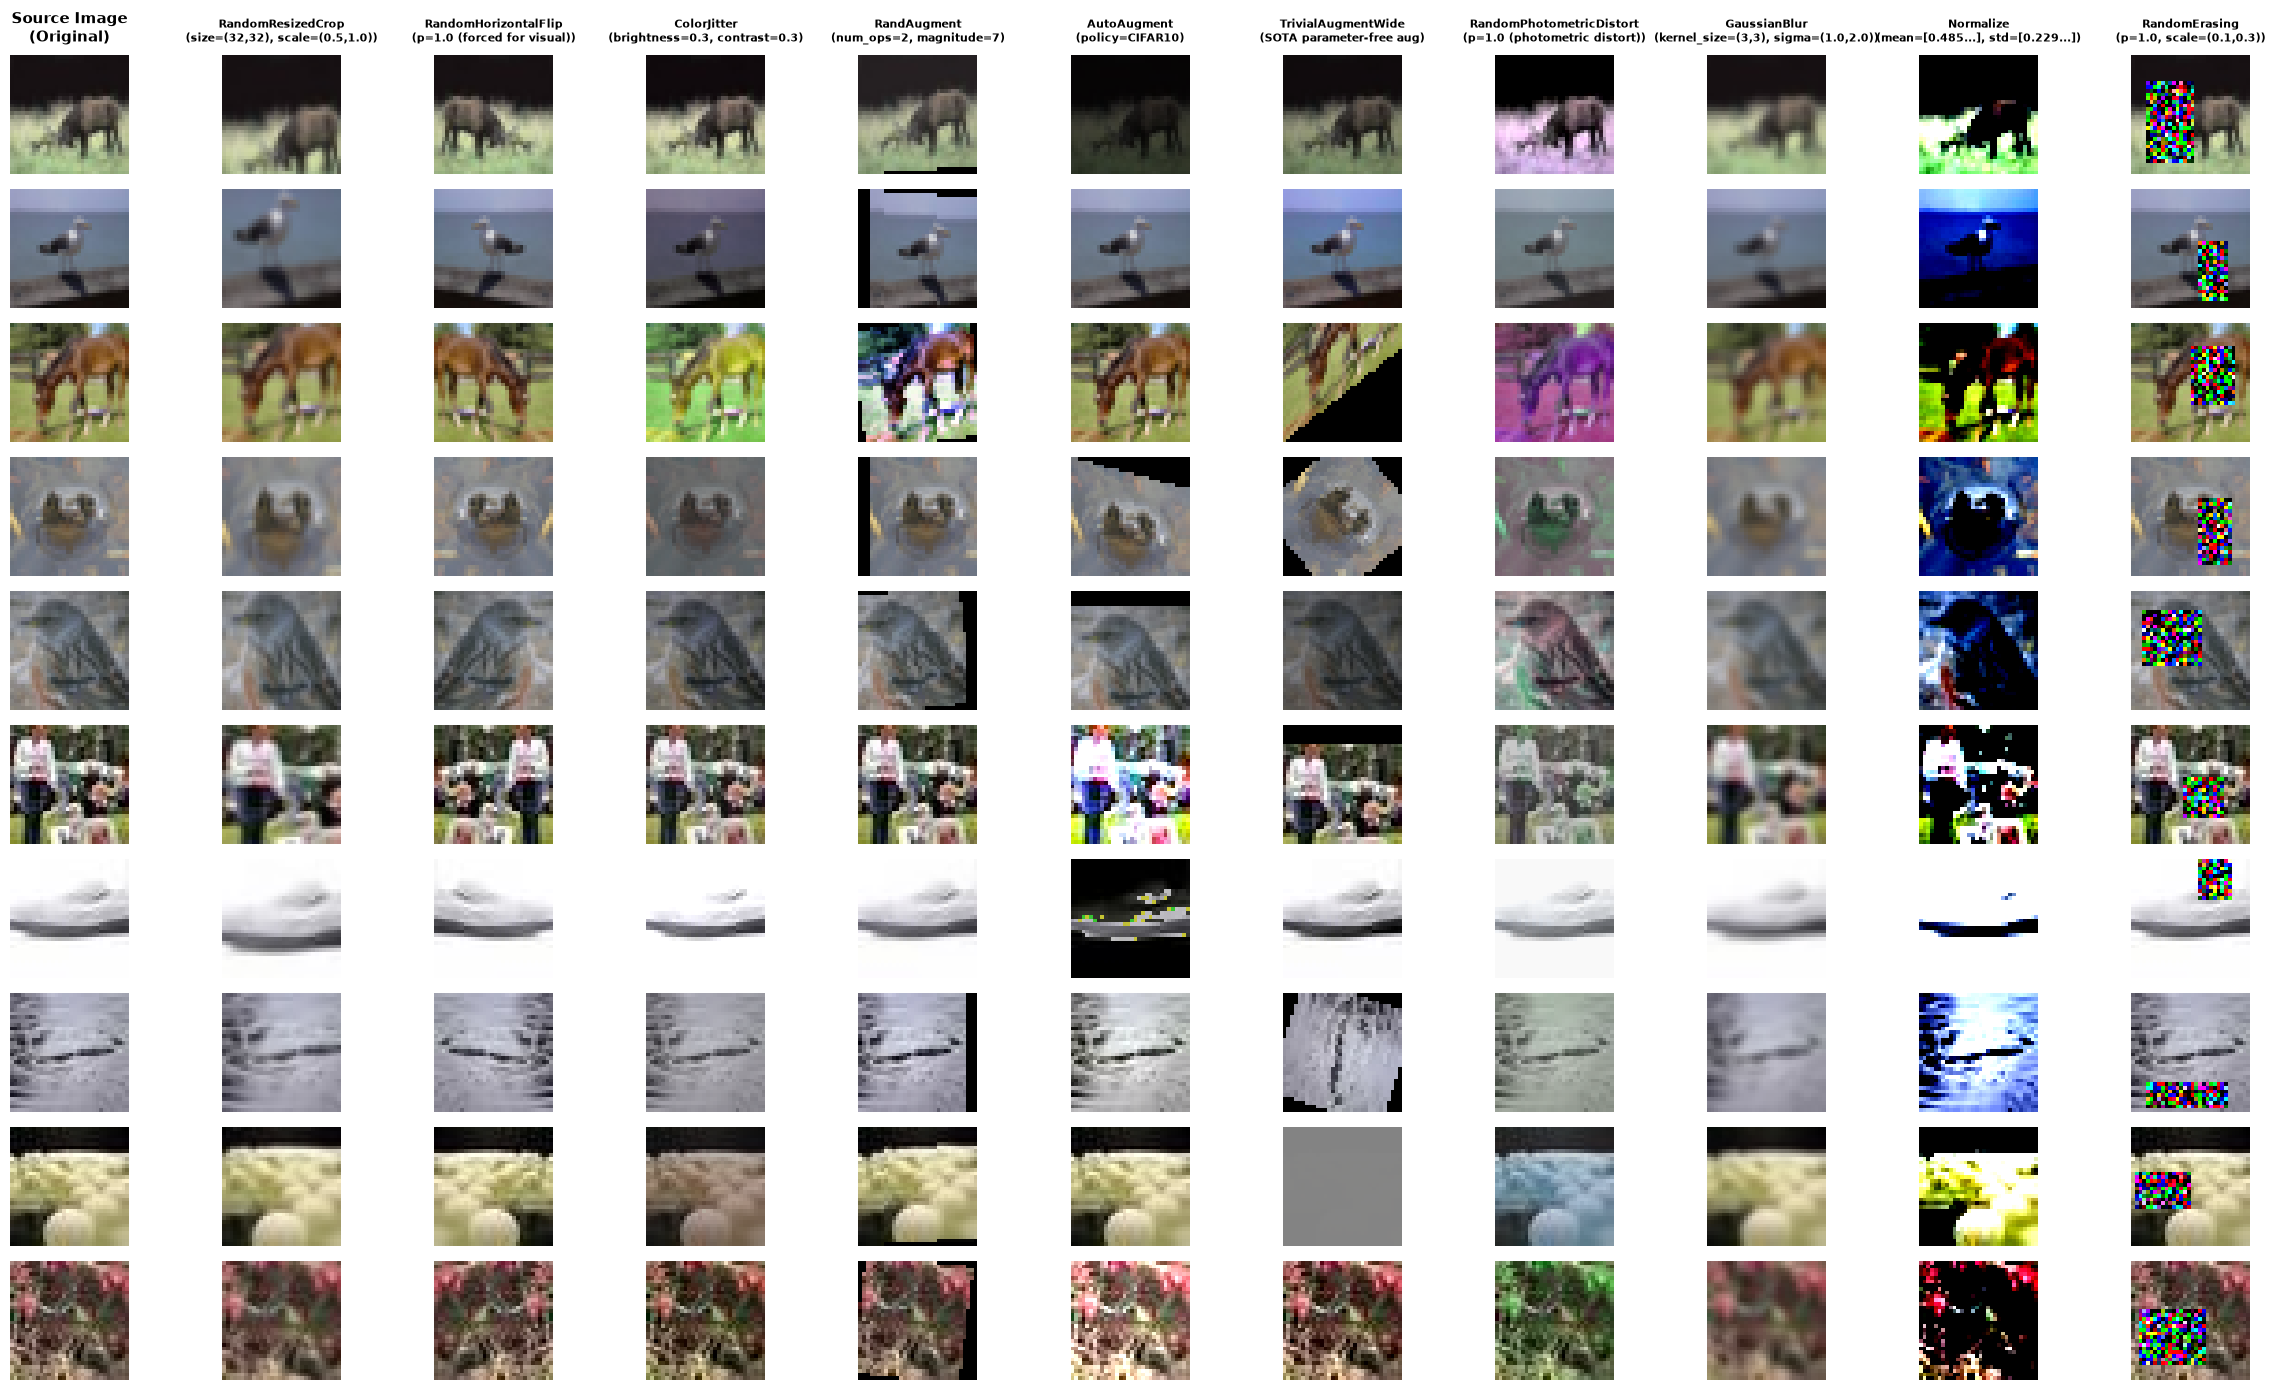

In [32]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. IMPORT VISION V2 TRANSFORMS
import torchvision.transforms.v2 as v2

# Flatten image tensor: (2, 3, 3, 32, 32) -> (6, 3, 32, 32)
sample_images = torch.flatten(stacked, start_dim=0, end_dim=1)

if sample_images.dtype == torch.uint8:
    sample_images = sample_images.float() / 255.0
elif sample_images.max() > 1.0:
    sample_images = sample_images / 255.0

# Ensure labels are standard Python strings/ints
if isinstance(labels, torch.Tensor):
    image_labels = labels.flatten().tolist()
else:
    image_labels = np.array(labels).flatten().tolist()

# -------------------------------------------------------------------------
# 2. DEFINE TOP 10 MODERN V2 TRANSFORMATIONS
# -------------------------------------------------------------------------
# V2 handles PyTorch Tensors natively — no ToTensor() calls needed!
transform_definitions = [
    (
        "RandomResizedCrop",
        v2.RandomResizedCrop(size=(32, 32), scale=(0.5, 1.0)),
        "size=(32,32), scale=(0.5,1.0)"
    ),
    (
        "RandomHorizontalFlip",
        v2.RandomHorizontalFlip(p=1.0),
        "p=1.0 (forced for visual)"
    ),
    (
        "ColorJitter",
        # Moderate factors (0.2 - 0.3) prevent extreme brightness overload
        v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        "brightness=0.3, contrast=0.3"
    ),
    (
        "RandAugment",
        v2.RandAugment(num_ops=2, magnitude=7),
        "num_ops=2, magnitude=7"
    ),
    (
        "AutoAugment",
        v2.AutoAugment(policy=v2.AutoAugmentPolicy.CIFAR10),
        "policy=CIFAR10"
    ),
    (
        "TrivialAugmentWide",
        v2.TrivialAugmentWide(),
        "SOTA parameter-free aug"
    ),
    (
        "RandomPhotometricDistort",
        # v2 built-in default parameters work cleanly on [0.0, 1.0] float tensors
        v2.RandomPhotometricDistort(p=1.0),
        "p=1.0 (photometric distort)"
    ),
    (
        "GaussianBlur",
        v2.GaussianBlur(kernel_size=(3, 3), sigma=(1.0, 2.0)),
        "kernel_size=(3,3), sigma=(1.0,2.0)"
    ),
    (
        "Normalize",
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        "mean=[0.485...], std=[0.229...]"
    ),
    (
        "RandomErasing",
        v2.RandomErasing(p=1.0, scale=(0.1, 0.3), value='random'),
        "p=1.0, scale=(0.1,0.3)"
    )
]


# -------------------------------------------------------------------------
# 3. HELPER FUNCTION FOR DISPLAY
# -------------------------------------------------------------------------
def denormalize_and_format(img_obj):
    if isinstance(img_obj, torch.Tensor):
        if img_obj.ndim == 4:
            img_obj = img_obj.squeeze(0)
            
        img_np = img_obj.detach().cpu().permute(1, 2, 0).numpy()
        
        # Clamp values to valid image range [0.0, 1.0]
        img_np = np.clip(img_np, 0.0, 1.0)
        return img_np
    else:
        return np.array(img_obj)

# -------------------------------------------------------------------------
# 4. PLOT SOURCE VS TRANSFORMED IMAGES
# -------------------------------------------------------------------------
num_images = len(sample_images)
num_transforms = len(transform_definitions)

fig, axes = plt.subplots(nrows=num_images, ncols=num_transforms + 1, figsize=(24, 14))

for row_idx, (img, label) in enumerate(zip(sample_images, image_labels)):
    # Plot Original Source Image
    display_src_img = denormalize_and_format(img.float())
    axes[row_idx, 0].imshow(display_src_img)
    
    if row_idx == 0:
        axes[row_idx, 0].set_title("Source Image\n(Original)", fontsize=11, fontweight='bold', pad=10)
    axes[row_idx, 0].set_ylabel(str(label), fontsize=10, fontweight='bold')
    axes[row_idx, 0].axis('off')
    
    # Apply and Display Transforms
    for col_idx, (name, transform_fn, params_str) in enumerate(transform_definitions):
        ax = axes[row_idx, col_idx + 1]
        
        # V2 accepts PyTorch Tensors directly without crashing!
        transformed_img = transform_fn(img.float())
        
        display_img = denormalize_and_format(transformed_img)
        ax.imshow(display_img)
        
        if row_idx == 0:
            ax.set_title(f"{name}\n({params_str})", fontsize=8, fontweight='bold', pad=10)
            
        ax.axis('off')

plt.tight_layout()
plt.show()